In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/cleaned_patient_dataset.csv")

print(df.shape)
df.head()

(5000, 29)


,Age,Gender,Height_cm,Weight_kg,BMI,Chronic_Disease,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol_Level,Blood_Sugar_Level,...,Protein_Intake,Carbohydrate_Intake,Fat_Intake,Preferred_Cuisine,Food_Aversions,Recommended_Calories,Recommended_Protein,Recommended_Carbs,Recommended_Fats,Recommended_Meal_Plan
0,56,Other,163,66,24.84,No Disease,175,75,219,124,...,105,179,143,Western,NaN,2150,108,139,145,High-Protein Diet
1,69,Female,171,114,38.99,No Disease,155,72,208,72,...,69,315,75,Mediterranean,NaN,1527,74,266,80,Low-Carb Diet
2,46,Female,172,119,40.22,No Disease,137,101,171,145,...,183,103,148,Western,Sweet,2359,180,145,143,Low-Carb Diet
3,32,Female,197,118,30.41,No Disease,148,91,258,235,...,135,371,120,Western,NaN,2858,137,378,135,Low-Carb Diet
4,60,Female,156,109,44.79,Hypertension,160,109,260,248,...,167,298,48,Indian,Spicy,1937,166,317,56,Low-Carb Diet


Knowledge base

In [2]:
RULES = {

    "Underweight":
        "High-Protein Diet",

    "Normal":
        "Balanced Diet",

    "Overweight":
        "Balanced Diet",

    "Obese":
        "Low-Carb Diet",

    "Diabetes":
        "Low-Carb Diet",

    "Heart Disease":
        "Low-Fat Diet",

    "Hypertension":
        "Low-Fat Diet"

}

In [4]:
def expert_recommendation(row):

    bmi = row["BMI"]
    disease = row["Chronic_Disease"]

    # Disease Rules (Highest Priority)
    if disease == "Heart Disease":
        return "Low-Fat Diet"

    elif disease == "Diabetes":
        return "Low-Carb Diet"

    elif disease == "Hypertension":
        return "Low-Fat Diet"

    # BMI Rules
    if bmi < 18.5:
        return "High-Protein Diet"

    elif bmi < 25:
        return "Balanced Diet"

    elif bmi < 30:
        return "Balanced Diet"

    else:
        return "Low-Carb Diet"

In [5]:
df["Expert_Meal_Plan"] = df.apply(
    expert_recommendation,
    axis=1
)

df[["BMI", "Chronic_Disease", "Expert_Meal_Plan"]].head(10)

,BMI,Chronic_Disease,Expert_Meal_Plan
0,24.84,No Disease,Balanced Diet
1,38.99,No Disease,Low-Carb Diet
2,40.22,No Disease,Low-Carb Diet
3,30.41,No Disease,Low-Carb Diet
4,44.79,Hypertension,Low-Fat Diet
5,27.71,Diabetes,Low-Carb Diet
6,15.40,Hypertension,Low-Fat Diet
7,31.71,Hypertension,Low-Fat Diet
8,44.20,Heart Disease,Low-Fat Diet
9,39.45,Heart Disease,Low-Fat Diet


In [6]:
df["Expert_Meal_Plan"].value_counts()

Expert_Meal_Plan
Low-Carb Diet        2066
Low-Fat Diet         1442
Balanced Diet        1208
High-Protein Diet     284
Name: count, dtype: int64

In [7]:
comparison = pd.crosstab(
    df["Recommended_Meal_Plan"],
    df["Expert_Meal_Plan"],
    margins=True
)

comparison

Expert_Meal_Plan,Balanced Diet,High-Protein Diet,Low-Carb Diet,Low-Fat Diet,All
Recommended_Meal_Plan,,,,,
Balanced Diet,257,54,0,90,401
High-Protein Diet,302,66,0,108,476
Low-Carb Diet,0,0,2066,272,2338
Low-Fat Diet,649,164,0,972,1785
All,1208,284,2066,1442,5000


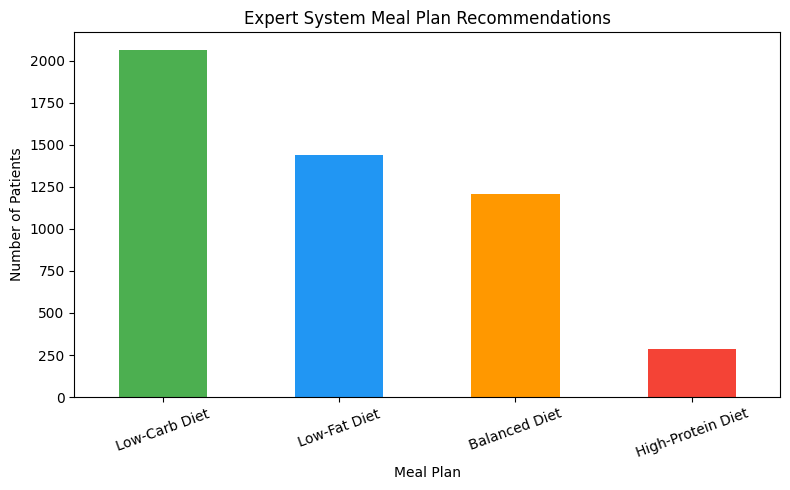

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

df["Expert_Meal_Plan"].value_counts().plot(
    kind="bar",
    color=["#4CAF50", "#2196F3", "#FF9800", "#F44336"]
)

plt.title("Expert System Meal Plan Recommendations")
plt.xlabel("Meal Plan")
plt.ylabel("Number of Patients")
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig("../reports/figures/expert_meal_plan_distribution.png")

plt.show()